In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def read_dem(tif_path):
    with rasterio.open(tif_path) as src:
        dem_data = src.read(1)  # 读取 DEM 数据
    return dem_data


dem_t1 = read_dem('H:\ICESat-2\Region4_map\Morecambe_map\A2022\Morecambe_2022_4_RF_FB6_new10_bys.tif')
dem_t2 = read_dem('H:\ICESat-2\Region4_map\Morecambe_map\A2023\Morecambe_2023_4_RF_FB6_new10_bys.tif')

def plot_3d(dem_data, time_point):
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    
    x = np.arange(dem_data.shape[1])  # x轴坐标
    y = np.arange(dem_data.shape[0])  # y轴坐标
    x, y = np.meshgrid(x, y)  # 创建网格
    
    ax.plot_surface(x, y, dem_data, cmap='terrain', edgecolor='none')
    ax.set_title(f"3D DEM at Time {time_point}")
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Elevation')
    
    plt.show()

# 示例：绘制时间点1的 DEM 数据
plot_3d(dem_t1, time_point=1)
plot_3d(dem_t2, time_point=2)

In [2]:
import numpy as np

def calculate_slope(dem_data):
    # 计算坡度，利用 numpy 的梯度函数
    dx, dy = np.gradient(dem_data)  # 计算每个方向的梯度
    slope = np.sqrt(dx**2 + dy**2)  # 使用勾股定理计算坡度
    return slope

# 计算坡度
slope = calculate_slope(dem_t1)

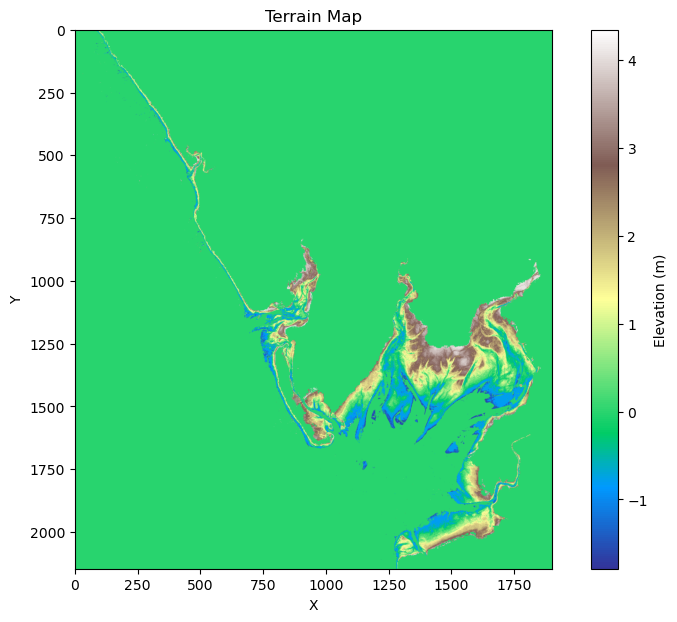

In [2]:
import matplotlib.pyplot as plt

def plot_terrain(dem_data):
    plt.figure(figsize=(10, 7))
    plt.imshow(dem_data, cmap='terrain')  # 使用 terrain 颜色映射，生成地形图
    plt.colorbar(label="Elevation (m)")
    plt.title("Terrain Map")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.show()

# 绘制地形图
plot_terrain(dem_t1)

In [9]:
# 检查 DEM 数据是否有 NaN 或无效值
if np.any(np.isnan(dem_t1)):
    print("数据包含 NaN 值，请清理数据！")

(2147, 1901)


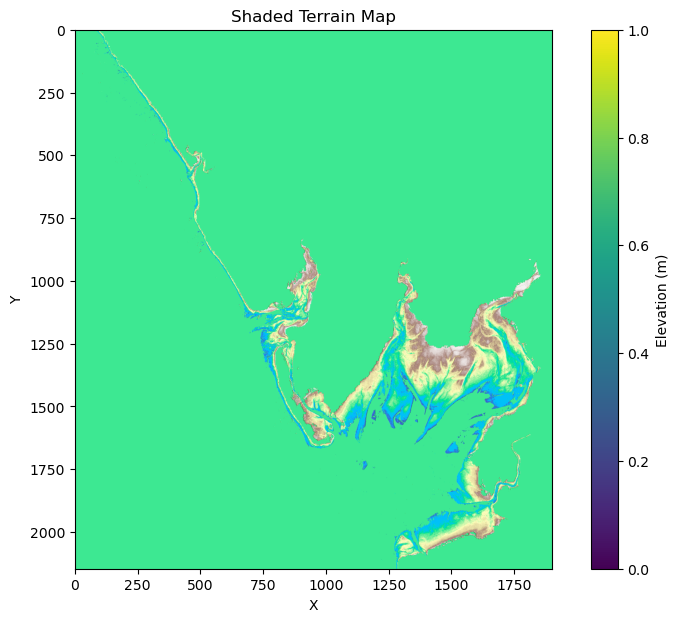

In [77]:
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import numpy as np

def plot_terrain_with_shading(dem_data):
    # 确保 dem_data 是浮动类型
    dem_data = dem_data.astype(np.float32)
    print(dem_data.shape)
    # 使用 LightSource 创建光照效果
    ls = LightSource(azdeg=80, altdeg=45)  # 设置光照方向
    shaded = ls.shade(dem_data, cmap=plt.cm.terrain, blend_mode='soft')  # 使用 plt.cm.terrain 而不是 'terrain'
    
    plt.figure(figsize=(10, 7))
    plt.imshow(shaded)
    plt.colorbar(label="Elevation (m)")
    plt.title("Shaded Terrain Map")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.show()

# 假设你已经有了 DEM 数据（如：dem_t1）
plot_terrain_with_shading(dem_t1)

In [76]:
dem_data.shape

NameError: name 'dem_data' is not defined

In [39]:
import rasterio
from rasterio.windows import Window
import numpy as np

def read_tif_window(tif_path, row_start, row_end, col_start, col_end):
    with rasterio.open(tif_path) as src:
        
        # 定义窗口
        window = Window(
            col_off=col_start,
            row_off=row_start,
            width=col_end - col_start,
            height=row_end - row_start
        )
        
        # 读取子区域
        dem = src.read(1, window=window)
        
        # 获取对应 transform（关键！保证坐标正确）
        transform = src.window_transform(window)
        
        # 生成经纬度
        rows, cols = np.indices(dem.shape)
        xs, ys = rasterio.transform.xy(transform, rows, cols)
        lon = np.array(xs)
        lat = np.array(ys)

    return lon, lat, dem

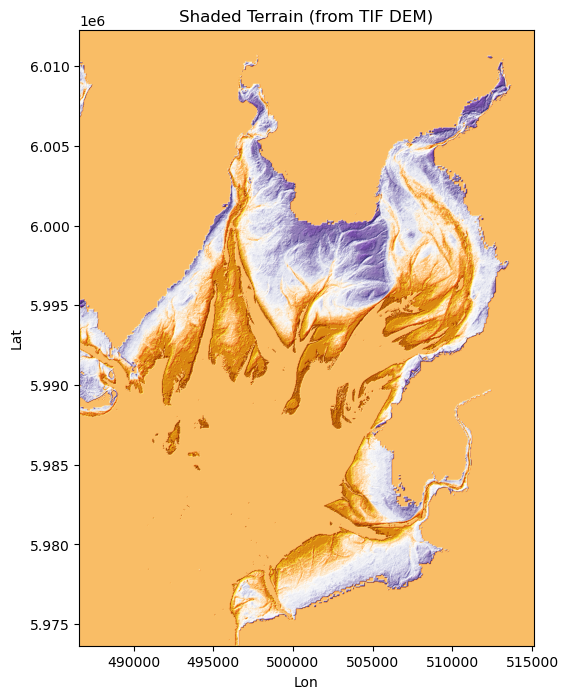

In [60]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource

# === 1. 读取 tif ===
def read_tif(tif_path):
    with rasterio.open(tif_path) as src:
        dem = src.read(1)
        transform = src.transform
        
        # 生成经纬度（关键！！）
        rows, cols = np.indices(dem.shape)
        xs, ys = rasterio.transform.xy(transform, rows, cols)
        lon = np.array(xs)
        lat = np.array(ys)
        
    return lon, lat, dem

lon, lat, dem = read_tif(r'H:/ICESat-2/Region4_map/Morecambe_map/A2022/Morecambe_2022_4_RF_FB6_new10_bys.tif')
with rasterio.open(r'H:/ICESat-2/Region4_map/Morecambe_map/A2022/Morecambe_2022_4_RF_FB6_new10_bys.tif') as src:
    h, w = src.height, src.width

# 取右下角 1/4
lon, lat, dem = read_tif_window(
    'H:/ICESat-2/Region4_map/Morecambe_map/A2019/Morecambe_2019_4_RF_FB6_new10_bys.tif',
    row_start=int(h*0.4),
    row_end=h,
    col_start=int(w*0.5),
    col_end=w
)

# === 2. 处理数据 ===
dem = dem.astype(np.float32)

# 去掉异常值（很关键，不然会炸）
dem[dem < -100] = np.nan

# === 3. 光照模型 ===
ls = LightSource(azdeg=315, altdeg=10)

from matplotlib.colors import Normalize

# 归一化的方式控制亮度范围（降低亮度）
norm = Normalize(vmin=-2, vmax=5) 

rgb = ls.shade(
    dem,
    cmap=plt.cm.PuOr,
    # cmap=plt.cm.terrain,
    blend_mode='overlay',   # ⭐ 比 soft 更适合地形
    vert_exag=5,            # ⭐ 关键参数（不是简单 z_scale）
    dx=1,
    dy=1,
    fraction=1.0   ,       # ⭐ 控制对比度
    norm = norm
)

# === 4. 绘图 ===
plt.figure(figsize=(10, 8))
plt.imshow(
    rgb,
    extent=(lon.min(), lon.max(), lat.min(), lat.max())
)

plt.title("Shaded Terrain (from TIF DEM)")
plt.xlabel("Lon")
plt.ylabel("Lat")
plt.show()

In [72]:
rgb.shape

(2147, 1901, 4)

In [43]:
import matplotlib.pyplot as plt
print(plt.colormaps())  # 打印所有可用的色带

['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'berlin', 'managua', 'vanimo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'grey', 'gist_grey', 'gist_yerg', 'Grays', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_shifted_r', 't

In [3]:
import os
import numpy as np
import imageio
import rasterio
import matplotlib.pyplot as plt
from io import BytesIO
from PIL import Image

# 输入路径和输出路径
input_folder = r'H:\ICESat-2\GIF_generate\Morecambe'  # 替换为你的.tif所在文件夹路径
output_gif = r'H:\ICESat-2\GIF_generate\Morecambe_output_.gif'

# 读取所有.tif文件
tif_files = sorted([f for f in os.listdir(input_folder) if f.endswith('.tif')])
frames = []

for tif in tif_files:
    filepath = os.path.join(input_folder, tif)
    with rasterio.open(filepath) as src:
        # 读取 DEM 数据
        data = src.read(1)  # 假设是单波段的 DEM 数据
        
        # 可视化处理（使用terrain色带）
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.axis('off')
        ax.imshow(data, cmap='terrain', vmin=data.min(), vmax=data.max())  # 可视化为地形图
        plt.colorbar(ax.imshow(data, cmap='terrain', vmin=data.min(), vmax=data.max()), ax=ax)

        # 将 matplotlib 图像保存到内存中
        buf = BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0)
        buf.seek(0)
        img = Image.open(buf)
        frames.append(img.copy())  # 添加帧到列表
        buf.close()
        plt.close()

# 保存为GIF
frames[0].save(output_gif, save_all=True, append_images=frames[1:], duration=800, loop=0)